# Racial concentration stats

In [23]:
import matplotlib.pyplot as plot
import numpy as np
import pandas as pd
import re
import statsmodels.formula.api as sm

In [27]:
school_df = pd.read_csv( '../../data/enrollment/merged/sfusd-school-ethnicity-sum.csv' )
elementary_df = school_df \
    [lambda _df: _df['ACADEMIC_YEAR'] == '2024-25'] \
    [lambda _df: ~(
        _df['SCHOOL'].str.contains( 'High' )
        | _df['SCHOOL'].str.contains( 'Middle' )
        | _df['SCHOOL'].str.contains( 'Charter' )
        | _df['SCHOOL'].str.contains( 'KIPP' )
        | _df['SCHOOL'].str.contains( 'Center' )
    )] \
    [lambda _df: ~_df['SCHOOL'].isin( [
        'District Office',
        'Nonpublic, Nonsectarian Schools',
        'Jordan (June) School for Equity',
        'City Arts & Leadership Academy',
        'Five Keys Independence HS (SF Sheriff\'s)',
        'Academy (The)- SF @McAteer',
        'The New School of San Francisco',
        'Mission Preparatory',
        'S.F. County Court Woodside Learning Ctr',
        'Asawa (Ruth) SF Sch of the Arts, A Public School',
        'S.F. County Opportunity (Hilltop)',
        'S.F. County Special Education',
    ])]
aa_concentration_df = pd.read_csv( './sfusd_racial_concentration_census2020_by_attendance_area.csv' )

all_races_enrollment = [
    'African American',
    'American Indian or Alaska Native',
    'Asian',
    'Filipino',
    'Hispanic or Latino',
    'Not Reported',
    'Pacific Islander',
    'Two or More Races',
    'White'
]
all_races_aa = [
    'aian',
    'asian',
    'black',
    'hispanic',
    'nhpi',
    'other',
    'two_or_more',
    'white'
]

In [31]:
#
# The AA concentration data only has information for elementary schools, because that's what we grabbed
#
export_df = elementary_df \
    .assign( e_aa_name = lambda _df: _df['SCHOOL'].apply( lambda r: r.upper().split( ' ' )[0] ) ) \
    .assign( e_aa_name = lambda _df: _df['e_aa_name'].map( {
        'EL':         'EL DORADO',
        'GLEN':       'GLEN PARK',
        'MALCOLM':    'MALCOLM X',
        'NEW':        'NEW TRADITIONS',
        'SPRING':     'SPRING VALLEY',
        'VISITACION': 'VISITACION VALLEY',
        'WEST':       'WEST PORTAL',
        'YICK':       'YICK WO'
    } ).fillna( _df['e_aa_name'] ) ) \
    .merge( aa_concentration_df, on = 'e_aa_name', how = 'outer', indicator = True ) \
    [lambda _df: _df['_merge'] == 'both'] \
    .assign( CDS_CODE = lambda _df: _df['CDS_CODE'].astype( int ) )

export_cols = [ 'ACADEMIC_YEAR', 'CDS_CODE', 'SCHOOL' ]
for col in all_races_enrollment:
    export_col_base = f"{re.sub( r'[^a-z]+', '_', col.lower() )}_enrollment"

    export_col_count = f"{export_col_base}_count"
    export_df = export_df.assign( **{ export_col_count: export_df[col].astype( int ) } )
    export_cols.append( export_col_count )

    export_col_pct = f"{export_col_base}_pct"
    export_df = export_df.assign( **{ export_col_pct: export_df[export_col_count] / export_df[all_races_enrollment].sum( axis = 1 ) } )
    export_cols.append( export_col_pct )

for col in all_races_aa:
    export_col_base = f"{col}_aa_child"

    export_col_count = f"{export_col_base}_count"
    export_df = export_df.assign( **{ export_col_count: export_df[f"{col}_5_9"].astype( int ) } )
    export_cols.append( export_col_count )

    export_col_pct = f"{export_col_base}_pct"
    export_df = export_df.assign( **{ export_col_pct: export_df[export_col_count] / export_df[[ f"{col}_5_9" for col in all_races_aa ]].sum( axis = 1 ) } )
    export_cols.append( export_col_pct )

export_df[export_cols].to_csv( 'elementary-ethnicity-enrollment-vs-aa.csv', index = False )

#
# Citywide:
# * BVHM
# * Carmichael
# * Chinese Immersion
# * Huerta
# * Lilienthal
# * Lawton
# * Lee
# * Marshall
# * Mission Ed
# * Montessori
# * Reverse
# * Rooftop
# * SF Community
# * Yu
#

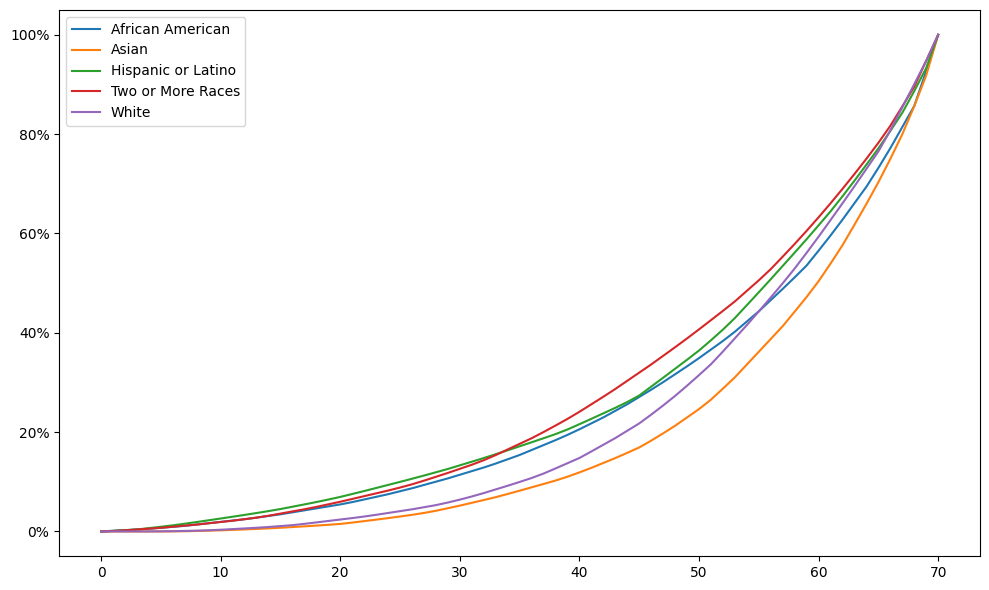

In [ ]:
all_races = [
    'African American',
    'American Indian or Alaska Native',
    'Asian',
    'Filipino',
    'Hispanic or Latino',
    'Not Reported',
    'Pacific Islander',
    'Two or More Races',
    'White'
]
plot_exclude_races = [ 'American Indian or Alaska Native', 'Filipino', 'Not Reported', 'Pacific Islander' ]
races = [ race for race in all_races if race not in plot_exclude_races ]

figure, axes = plot.subplots( figsize = ( 10, 6 ) )

for race in races:
    plot_df = df \
        [[race]] \
        .sort_values( race ) \
        .reset_index( drop = True ) \
        .reset_index() \
        .assign( cumsum = lambda _df: _df[race].cumsum() ) \
        .assign( CDF = lambda _df: _df['cumsum'] / _df[race].sum() )
    
    axes.plot( plot_df['index'], plot_df['CDF'], label = race )

axes.legend( loc = 'best' )
axes.yaxis.set_major_formatter( '{x:0.0%}' )

plot.tight_layout()
plot.show()

Running for Hispanic or Latino


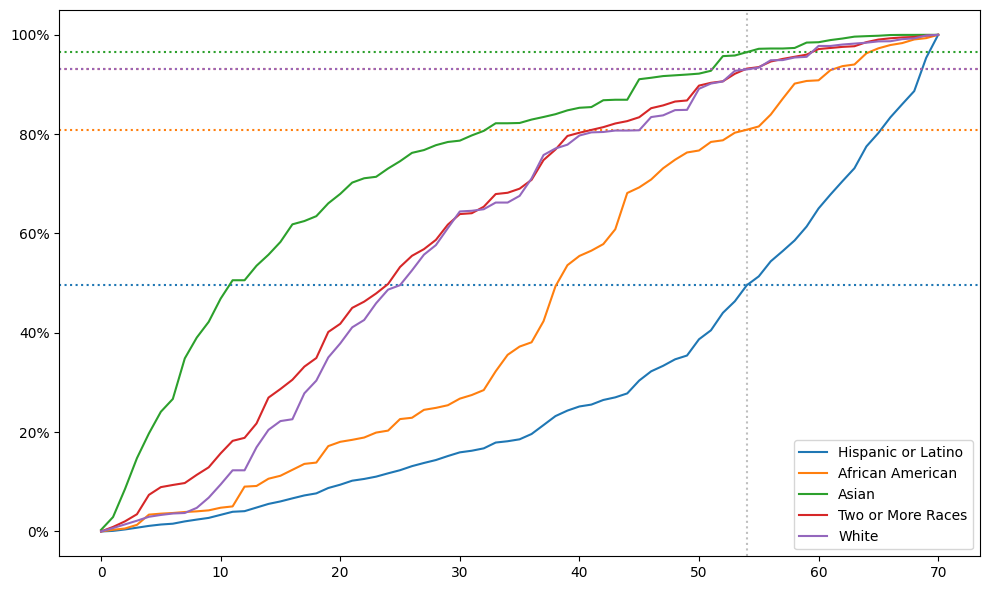

In [113]:
base_race = all_races[4] #'African American'
print( f'Running for {base_race}' )
plot_df = df \
    .assign( aa_pct = lambda _df: _df[base_race] / _df[all_races].sum( axis = 1 ) ) \
    .sort_values( 'aa_pct' ) \
    .reset_index( drop = True ) \
    .reset_index()

figure, axes = plot.subplots( figsize = ( 10, 6 ) )

races = [ base_race, *[ race for race in races if race != base_race ] ]

for race in races:
    plot_df = plot_df \
        .assign( cumsum = lambda _df: _df[race].cumsum() ) \
        .assign( CDF = lambda _df: _df['cumsum'] / _df[race].sum() )
    
    if race == base_race:
        ix = np.argmin( np.abs( plot_df['CDF'] - 0.5 ) )
        axes.axvline( ix, linestyle = ':', color = 'grey', alpha = 0.5 )
    
    handle = axes.plot( plot_df['index'], plot_df['CDF'], label = race )
    axes.axhline( plot_df.iloc[ix]['CDF'], linestyle = ':', color = handle[0].get_color() )

axes.legend( loc = 'best' )
axes.yaxis.set_major_formatter( '{x:0.0%}' )

plot.tight_layout()
plot.show()

In [122]:
rai_df = pd.read_csv( '../closure-summary/rai-elementary-summary.csv' ) \
    .merge( df.rename( columns = { 'SCHOOL': 'School' } ), how = 'outer' ) \
    [lambda _df: ~pd.isnull( _df['RAI score'] )] \
    .assign( closure_indicator = lambda _df: np.where( _df['was_closing'] | _df['was_merging'], 1, 0 ) )

for race in races:
    rai_df = rai_df.assign( **{ f'{race} pct': rai_df[race] / rai_df[all_races].sum( axis = 1 ) } )

reg_df = rai_df \
    [['RAI score','closure_indicator',*[ f'{race} pct' for race in races]]] \
    .rename( columns = lambda c: re.sub( r'[^\w]+', '_', c ) )
reg_df.loc[34,'closure_indicator'] = 1
weight_df = rai_df[all_races].sum( axis = 1 )
# display( reg_df[reg_df.closure_indicator ==1 ])

formula = f"RAI_score ~ {'+'.join( [ col for col in reg_df if col not in [ 'RAI_score', 'closure_indicator', 'African_American_pct' ] ] )}"
print( f"""
Regression 1:
{formula}
""".strip() )
ols = sm.wls( formula, reg_df, weights = weight_df )
ols = ols.fit()
display( ols.summary() )

ols = sm.wls( f"African_American_pct ~ closure_indicator", reg_df, weights = weight_df )
ols = ols.fit()
ols.summary()

Regression 1:
RAI_score ~ Hispanic_or_Latino_pct+Asian_pct+Two_or_More_Races_pct+White_pct


<class 'statsmodels.iolib.summary.Summary'>
"""
                            WLS Regression Results                            
==============================================================================
Dep. Variable:              RAI_score   R-squared:                       0.294
Model:                            WLS   Adj. R-squared:                  0.249
Method:                 Least Squares   F-statistic:                     6.552
Date:                Fri, 20 Feb 2026   Prob (F-statistic):           0.000179
Time:                        00:25:55   Log-Likelihood:                -262.35
No. Observations:                  68   AIC:                             534.7
Df Residuals:                      63   BIC:                             545.8
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 14.9865     15.804      0.948      0.347     -16.596      46.569
Hispanic_or_Latino_pct    27.4547     18.307      1.500      0.139      -9.129      64.038
Asian_pct                 12.3753     16.397      0.755      0.453     -20.392      45.143
Two_or_More_Races_pct    128.7756     45.760      2.814      0.007      37.332     220.219
White_pct                -49.8646     18.512     -2.694      0.009     -86.858     -12.872
==============================================================================
Omnibus:                        3.660   Durbin-Watson:                   2.032
Prob(Omnibus):                  0.160   Jarque-Bera (JB):                3.061
Skew:                           0.514   Prob(JB):                        0.216
Kurtosis:                       3.147   Cond. No.                         41.4
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

<class 'statsmodels.iolib.summary.Summary'>
"""
                             WLS Regression Results                             
================================================================================
Dep. Variable:     African_American_pct   R-squared:                       0.060
Model:                              WLS   Adj. R-squared:                  0.045
Method:                   Least Squares   F-statistic:                     4.185
Date:                  Fri, 20 Feb 2026   Prob (F-statistic):             0.0448
Time:                          00:25:55   Log-Likelihood:                 82.938
No. Observations:                    68   AIC:                            -161.9
Df Residuals:                        66   BIC:                            -157.4
Df Model:                             1                                         
Covariance Type:              nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             0.0495      0.009      5.724      0.000       0.032       0.067
closure_indicator     0.0702      0.034      2.046      0.045       0.002       0.139
==============================================================================
Omnibus:                       35.792   Durbin-Watson:                   2.189
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               76.963
Skew:                           1.808   Prob(JB):                     1.94e-17
Kurtosis:                       6.754   Cond. No.                         4.12
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
#
# Load the AA data
#
df = aa_concentration_df

suffix = '5_9'

print( f"""
We estimate there are {df['total_' + suffix].sum() / ( 6 if suffix == "k5" else 5 ) * 0.65 * 13:0.1f} students in SFUSD.

* {df['total_' + suffix].sum()} children in {'grades K-5' if suffix == 'k5' else 'ages 5-9'}
* x ( 13 / {6 if suffix == 'k5' else 5} ) for 13 total grades
* x 0.65 for 65% public-school enrollment
""" )


We estimate there are 59631.7 students in SFUSD.

* 35285.0 children in ages 5-9
* x ( 13 / 5 ) for 13 total grades
* x 0.65 for 65% public-school enrollment



In [62]:
threshold = 40

k5_pct_cols = [ col for col in df if re.search( f'pct_.*?_{suffix}', col ) ]
concentration_df = df[df.apply( lambda r: np.any( r[k5_pct_cols] > threshold ), axis = 1 )]

for _, row in concentration_df.iterrows():
    concentration_cols = [ col for col in k5_pct_cols if row[col] > threshold ]

    for col in concentration_cols:
        pretty_col = col.split( '_' )[1]
        pretty_col = pretty_col[0].upper() + pretty_col[1:]

        pretty_school = ' '.join( [ f'{p[0].upper()}{p[1:].lower()}' for p in row['e_aa_name'].split( ' ' ) ] )
        print( f"""
{pretty_school+' AA':18s} is {row[col]}% {pretty_col}.
""".strip() )
        
print( '***' )
        
df_adj = df.copy()
for col in k5_pct_cols:
    df_adj = df_adj.assign( **{ col: lambda _df: _df[col] * 0.82 } )
    
df_adj = df_adj \
    .assign( **{
        f'pct_white_{suffix}': lambda _df: _df[f'pct_white_{suffix}'] * 0.5 / 0.82
    } ) \
    .assign( **{
        f'pct_two_or_more_{suffix}': lambda _df: _df[f'pct_two_or_more_{suffix}'] * 0.6 / 0.82
    } ) \
    .assign( pct_adj = lambda _df: _df[k5_pct_cols].sum( axis = 1 ) )

for col in k5_pct_cols:
    df_adj = df_adj.assign( **{ col: lambda _df: _df[col] / _df['pct_adj' ] } )


concentration_df = df_adj[lambda _df: _df.apply( lambda r: np.any( r[k5_pct_cols] > threshold / 100 ), axis = 1 )]

for _, row in concentration_df.iterrows():
    concentration_cols = [ col for col in k5_pct_cols if row[col] > threshold / 100 ]

    for col in concentration_cols:
        pretty_col = col.split( '_' )[1]
        pretty_col = pretty_col[0].upper() + pretty_col[1:]

        pretty_school = ' '.join( [ f'{p[0].upper()}{p[1:].lower()}' for p in row['e_aa_name'].split( ' ' ) ] )
        print( f"""
{pretty_school+' AA':18s} is {row[col]:0.1%} {pretty_col}.
""".strip() )   

Alvarado AA        is 47.6% Hispanic.
Chavez AA          is 40.8% White.
Chin AA            is 44.0% Asian.
Clarendon AA       is 43.9% Hispanic.
Cobb AA            is 56.2% Hispanic.
El Dorado AA       is 43.1% Asian.
Feinstein AA       is 42.1% Asian.
Grattan AA         is 55.2% Hispanic.
Lau AA             is 66.2% Asian.
Longfellow AA      is 40.3% Asian.
Mckinley AA        is 48.0% Hispanic.
Milk AA            is 42.9% Hispanic.
Ortega AA          is 46.6% Asian.
Parker AA          is 82.3% Asian.
Peabody AA         is 45.1% Hispanic.
Sherman AA         is 48.9% Hispanic.
Stevenson AA       is 44.5% Asian.
Sunset AA          is 47.8% Asian.
Sutro AA           is 51.3% Hispanic.
Ulloa AA           is 48.4% Asian.
***
Alamo AA           is 44.3% Hispanic.
Alvarado AA        is 53.7% Hispanic.
Chin AA            is 48.0% Asian.
Clarendon AA       is 48.9% Hispanic.
Cobb AA            is 61.5% Hispanic.
El Dorado AA       is 48.3% Asian.
Feinstein AA       is 45.9% Asian.
Flynn AA    

In [57]:
#
# View enrollment figures
#
df = pd.read_csv( '../../data/enrollment/merged/sfusd-school-ethnicity-pct.csv' )
df = df \
    [df['ACADEMIC_YEAR'] == '2024-25'] \
    [lambda _df: _df['SCHOOL'].str.contains( 'Elem' ) | _df['SCHOOL'].str.contains( 'X' )]

race_cols = [ col for col in df if col != col.upper() ]
df = df[df.apply( lambda r: np.any( r[race_cols].astype( float ) > threshold / 100 ), axis = 1 )] \
    .sort_values( 'SCHOOL' )

for _, row in df.iterrows():
    concentration_cols = [ col for col in race_cols if row[col] > threshold / 100 ]

    for col in concentration_cols:
        pretty_col = col

        pretty_school = row['SCHOOL']
        print( f"""
{pretty_school:32s} is {row[col]:0.1%} {pretty_col}.
""".strip() )

Alvarado Elementary              is 48.3% Hispanic or Latino.
Bryant Elementary                is 88.2% Hispanic or Latino.
Carver (George Washington) Elementary is 53.8% African American.
Chavez (Cesar) Elementary        is 92.7% Hispanic or Latino.
Chin (John Yehall) Elementary    is 78.5% Asian.
Cleveland Elementary             is 83.3% Hispanic or Latino.
El Dorado Elementary             is 47.7% Hispanic or Latino.
Flynn (Leonard R.) Elementary    is 63.3% Hispanic or Latino.
Glen Park Elementary             is 53.2% Hispanic or Latino.
Grattan Elementary               is 50.5% White.
Guadalupe Elementary             is 75.8% Hispanic or Latino.
Harte (Bret) Elementary          is 63.8% Hispanic or Latino.
Hillcrest Elementary             is 70.7% Hispanic or Latino.
Huerta (Dolores) Elementary      is 69.4% Hispanic or Latino.
Jefferson Elementary             is 51.5% Asian.
KIPP Bayview Elementary          is 48.9% African American.
Lau (Gordon J.) Elementary       is 89.0% Asia

In [26]:
aa_concentration_df.columns

Index(['e_aa_name', 'total', 'hispanic', 'white', 'black', 'aian', 'asian',
       'nhpi', 'other', 'two_or_more', 'white_5_9', 'black_5_9', 'aian_5_9',
       'asian_5_9', 'nhpi_5_9', 'other_5_9', 'two_or_more_5_9', 'hispanic_5_9',
       'pct_white', 'pct_black', 'pct_aian', 'pct_asian', 'pct_nhpi',
       'pct_other', 'pct_two_or_more', 'pct_hispanic', 'total_5_9',
       'pct_white_5_9', 'pct_black_5_9', 'pct_aian_5_9', 'pct_asian_5_9',
       'pct_nhpi_5_9', 'pct_other_5_9', 'pct_two_or_more_5_9',
       'pct_hispanic_5_9'],
      dtype='object')